
# 05 — Final Model Evaluation

We evaluate the frozen XGBoost pipeline on the independent 2016 holdout.

The model was selected using validation PR-AUC, with all 55 raw features and a fixed classification threshold. This notebook measures generalization, calibration, risk ranking, and temporal stability.

The 2016 data will only be used for final evaluation, not model tuning.


In [1]:

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

src = str(root / "src")
if src not in sys.path:
    sys.path.insert(0, src)

from loanrisk.predict import load_model, predict_full

model_path = root / "saved_models/best_pipeline.pkl"
data_path = root / "data/interim/lendingclub_2013_2016_36m_raw.parquet"

assert model_path.exists(), "Saved model not found"
assert data_path.exists(), "Dataset not found"

bundle = load_model(model_path)

model = bundle["pipeline"]
raw_cols = bundle["raw_columns"]
threshold = float(bundle["threshold"])

assert len(raw_cols) == 55
assert 0 < threshold < 1
assert bundle["model_name"].lower() == "xgboost"

print("Model:", bundle["model_name"])
print("Raw features:", len(raw_cols))
print("Threshold:", round(threshold, 5))
print("Training:", bundle["training_period"])
print("Validation:", bundle["validation_period"])
print("Validation PR-AUC:",
      round(bundle["validation_metrics"]["pr_auc"], 5))

print("\nFrozen model verification: PASS")
print("2016 test data not loaded yet.")


Model: xgboost
Raw features: 55
Threshold: 0.1561
Training: 2013-01 to 2015-09
Validation: 2015-10 to 2015-12
Validation PR-AUC: 0.29912

Frozen model verification: PASS
2016 test data not loaded yet.



### 05.2 — Test Data Preparation

We load the independent 2016 cohort containing resolved 36-month loans. Before evaluation, we verify the date range, target labels, row count, and availability of all 55 model features.

The test set is kept separate from training and validation, with no additional preprocessing fitted on it.


In [2]:

import polars as pl
from datetime import date

# Load only 2016 loans and required columns
test_df = (
    pl.scan_parquet(data_path)
    .filter(
        (pl.col("issue_date") >= date(2016, 1, 1))
        & (pl.col("issue_date") < date(2017, 1, 1))
    )
    .select(["issue_date", "target"] + raw_cols)
    .collect()
    .to_pandas()
)

# Prepare inputs, labels, and dates
X_test = test_df[raw_cols].copy()
y_test = test_df["target"].to_numpy(dtype=np.int8)
test_dates = pd.to_datetime(test_df["issue_date"])

# Basic integrity checks
assert len(test_df) > 0
assert test_dates.notna().all()
assert test_dates.dt.year.eq(2016).all()
assert test_df["target"].notna().all()
assert set(np.unique(y_test)) == {0, 1}
assert X_test.shape[1] == 55
assert X_test.columns.tolist() == raw_cols

# Target distribution
class_counts = pd.Series(y_test).value_counts().sort_index()

print("2016 TEST COHORT")
print("-" * 35)
print("Total loans:", len(test_df))
print("Features:", X_test.shape[1])
print("Period:", test_dates.min().date(), "to",
      test_dates.max().date())

print("\nTarget distribution:")
for cls, count in class_counts.items():
    label = "Fully Paid" if cls == 0 else "Charged Off"
    print(f"Class {cls} ({label}): {count:,} ({count / len(y_test):.2%})")

print("\nMissing values:")
print("Columns with missing values:",
      int(X_test.isna().any().sum()))
print("Rows with any missing values:",
      f"{X_test.isna().any(axis=1).mean():.2%}")

print("\nTest data integrity: PASS")
print("No model fitting or threshold changes performed.")


2016 TEST COHORT
-----------------------------------
Total loans: 323375
Features: 55
Period: 2016-01-01 to 2016-12-01

Target distribution:
Class 0 (Fully Paid): 272,076 (84.14%)
Class 1 (Charged Off): 51,299 (15.86%)

Missing values:
Columns with missing values: 0
Rows with any missing values: 0.00%

Test data integrity: PASS
No model fitting or threshold changes performed.



### 05.3 — Final Test Performance

We evaluate the frozen XGBoost model on the independent 2016 holdout using the previously selected classification threshold.

We report PR-AUC, ROC-AUC, precision, recall, F1, balanced accuracy, and the confusion matrix. A majority-class baseline is included for comparison.

No retraining, threshold tuning, or model selection is performed using test data.


In [3]:

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
)

# Predict using the saved, frozen pipeline
test_predictions = predict_full(X_test, bundle)

p_test = test_predictions["default_risk_score"].to_numpy()
y_pred = test_predictions["predicted_default"].to_numpy()

# Majority-class baseline: predict Fully Paid for every loan
baseline_pred = np.zeros_like(y_test)

results = {
    "Majority baseline": {
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, baseline_pred),
        "Precision": precision_score(y_test, baseline_pred, zero_division=0),
        "Recall": recall_score(y_test, baseline_pred, zero_division=0),
        "F1": f1_score(y_test, baseline_pred, zero_division=0),
        "PR-AUC": y_test.mean(),
        "ROC-AUC": 0.5,
    },
    "XGBoost (2016)": {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_test, p_test),
        "ROC-AUC": roc_auc_score(y_test, p_test),
    },
}

metrics_df = pd.DataFrame(results).T

print("FINAL TEST PERFORMANCE")
display(metrics_df.round(4))

print("Threshold:", round(threshold, 5))
print("Test default rate:", f"{y_test.mean():.2%}")
print("Brier score:", round(brier_score_loss(y_test, p_test), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, y_pred,
    target_names=["Fully Paid (0)", "Charged Off (1)"],
    digits=4,
    zero_division=0,
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

cm_df = pd.DataFrame(
    cm,
    index=["Actual Fully Paid", "Actual Charged Off"],
    columns=["Predicted Fully Paid", "Predicted Charged Off"],
)

print("CONFUSION MATRIX")
display(cm_df)

# Compare validation and independent test performance
validation = bundle["validation_metrics"]

comparison = pd.DataFrame({
    "2015 Validation": {
        "PR-AUC": validation["pr_auc"],
        "ROC-AUC": validation["roc_auc"],
        "F1": validation["f1"],
        "Precision": validation["precision"],
        "Recall": validation["recall"],
        "Balanced accuracy": validation["balanced_accuracy"],
    },
    "2016 Test": {
        "PR-AUC": results["XGBoost (2016)"]["PR-AUC"],
        "ROC-AUC": results["XGBoost (2016)"]["ROC-AUC"],
        "F1": results["XGBoost (2016)"]["F1"],
        "Precision": results["XGBoost (2016)"]["Precision"],
        "Recall": results["XGBoost (2016)"]["Recall"],
        "Balanced accuracy": results["XGBoost (2016)"]["Balanced accuracy"],
    },
})

comparison["Test - Validation"] = (
    comparison["2016 Test"] - comparison["2015 Validation"]
)

print("VALIDATION VS TEST")
display(comparison.round(4))

print("Final holdout evaluation completed.")
print("No model or threshold modifications.")


FINAL TEST PERFORMANCE


,Accuracy,Balanced accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC
Majority baseline,0.8414,0.5000,0.0000,0.0000,0.0000,0.1586,0.500
XGBoost (2016),0.6780,0.6433,0.2675,0.5926,0.3686,0.3043,0.704


Threshold: 0.1561
Test default rate: 15.86%
Brier score: 0.1241

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

 Fully Paid (0)     0.9004    0.6940    0.7839    272076
Charged Off (1)     0.2675    0.5926    0.3686     51299

       accuracy                         0.6780    323375
      macro avg     0.5839    0.6433    0.5762    323375
   weighted avg     0.8000    0.6780    0.7180    323375

CONFUSION MATRIX


,Predicted Fully Paid,Predicted Charged Off
Actual Fully Paid,188832,83244
Actual Charged Off,20898,30401


VALIDATION VS TEST


,2015 Validation,2016 Test,Test - Validation
PR-AUC,0.2991,0.3043,0.0052
ROC-AUC,0.7149,0.7040,-0.0109
F1,0.3644,0.3686,0.0042
Precision,0.2693,0.2675,-0.0018
Recall,0.5637,0.5926,0.0289
Balanced accuracy,0.6485,0.6433,-0.0052


Final holdout evaluation completed.
No model or threshold modifications.



### 05.3 — Final Test Results

The frozen XGBoost model was evaluated on 323,375 loans issued in 2016, with a default rate of 15.86%.

The model achieved PR-AUC 0.3043, ROC-AUC 0.7040, F1 0.3686, precision 0.2675 and recall 0.5926 at the frozen threshold of 0.1561.

It correctly identified 30,401 defaults while missing 20,898. The relatively high false-positive count (83,244) reflects the precision-recall trade-off.

Performance remained broadly consistent with 2015 validation results, suggesting reasonable temporal generalization. However, the model is not sufficiently reliable for automated lending decisions without further validation and calibration assessment.

No model or threshold changes were made using test data.



### 05.4 — ROC and Precision–Recall Curves

We evaluate the frozen XGBoost model's ability to distinguish defaulters from non-defaulters using ROC and Precision–Recall curves.

ROC-AUC measures overall discrimination, while PR-AUC is particularly useful for our imbalanced dataset. We also mark the previously selected threshold (0.1561) to visualize its precision-recall and false-positive trade-offs.

The 2016 test data is used only for evaluation, without changing the model or threshold.


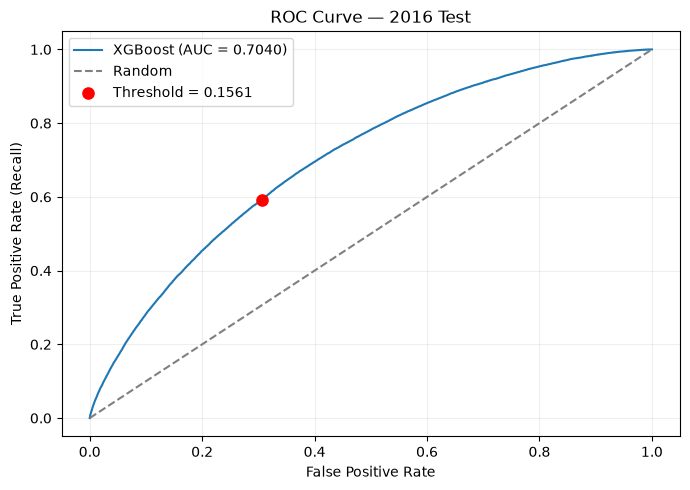

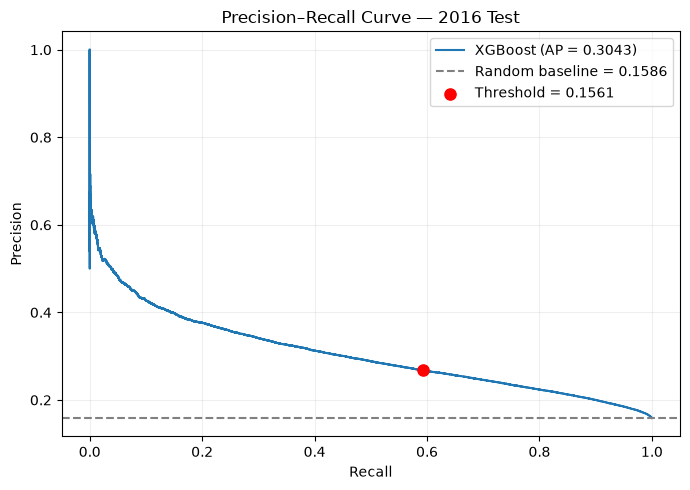

ROC-AUC: 0.7040
PR-AUC (Average Precision): 0.3043
Random PR baseline: 0.1586
Threshold: 0.1561
False Positive Rate: 0.3060
Precision at threshold: 0.2675
Recall at threshold: 0.5926


In [4]:

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix,
)
import matplotlib.pyplot as plt

# Calculate curves and metrics
fpr, tpr, _ = roc_curve(y_test, p_test)
precision, recall, _ = precision_recall_curve(y_test, p_test)

roc_auc = roc_auc_score(y_test, p_test)
pr_auc = average_precision_score(y_test, p_test)
default_rate = y_test.mean()

# Operating point at our frozen threshold
y_pred = (p_test >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

point_fpr = fp / (fp + tn)
point_tpr = tp / (tp + fn)
point_precision = precision_score(y_test, y_pred)
point_recall = recall_score(y_test, y_pred)

# ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"XGBoost (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random")
plt.scatter(
    point_fpr, point_tpr, color="red", s=65,
    zorder=5, label=f"Threshold = {threshold:.4f}"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — 2016 Test")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Precision–Recall curve
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"XGBoost (AP = {pr_auc:.4f})")
plt.axhline(
    default_rate, linestyle="--", color="gray",
    label=f"Random baseline = {default_rate:.4f}"
)
plt.scatter(
    point_recall, point_precision, color="red", s=65,
    zorder=5, label=f"Threshold = {threshold:.4f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — 2016 Test")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")
print(f"Random PR baseline: {default_rate:.4f}")
print(f"Threshold: {threshold:.4f}")
print(f"False Positive Rate: {point_fpr:.4f}")
print(f"Precision at threshold: {point_precision:.4f}")
print(f"Recall at threshold: {point_recall:.4f}")



### 05.4 — Results and Interpretation

The frozen XGBoost model achieved ROC-AUC 0.7040 and PR-AUC 0.3043 on the 2016 holdout, outperforming random baselines.

At the fixed threshold of 0.1561, recall was 59.26%, precision was 26.75%, and the false-positive rate was 30.60%.

The curves demonstrate useful risk discrimination but a significant precision-recall trade-off. The model is more suitable for risk ranking and loss prevention measure than automatic loan rejection. No threshold adjustments were made using test data.



### 05.5 — Probability Calibration

We examine whether the frozen model's predicted risk scores correspond to observed default frequencies.

Loans are divided into ten equal-sized groups based on predicted scores. We compare the average score with the actual default rate within each group.

Calibration is assessed without fitting a calibrator or modifying the saved model.


,loans,mean_score,actual_default_rate,difference
decile,,,,
1,32338,0.0272,0.0298,0.0026
2,32337,0.0511,0.0603,0.0092
3,32338,0.0710,0.0808,0.0098
4,32337,0.0898,0.1050,0.0152
5,32338,0.1094,0.1301,0.0208
6,32337,0.1311,0.1525,0.0214
7,32337,0.1567,0.1846,0.0279
8,32338,0.1887,0.2161,0.0274
9,32337,0.2340,0.2622,0.0282


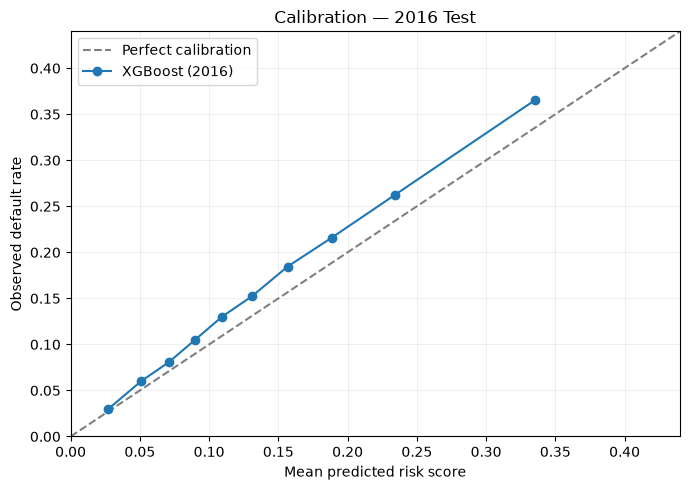

Mean predicted score: 0.1394
Actual default rate: 0.1586
Brier score: 0.1241
Calibration assessment only; model unchanged.


In [5]:

from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

# Build equal-sized risk groups
cal_df = pd.DataFrame({
    "score": p_test,
    "actual": y_test,
})

cal_df["decile"] = pd.qcut(
    cal_df["score"].rank(method="first"),
    q=10,
    labels=False,
) + 1

calibration = cal_df.groupby("decile").agg(
    loans=("actual", "size"),
    mean_score=("score", "mean"),
    actual_default_rate=("actual", "mean"),
)

calibration["difference"] = (
    calibration["actual_default_rate"]
    - calibration["mean_score"]
)

display(calibration.round(4))

# Calibration plot
limit = min(
    1.0,
    max(
        0.4,
        calibration["mean_score"].max(),
        calibration["actual_default_rate"].max(),
    ) * 1.1,
)

plt.figure(figsize=(7, 5))

plt.plot(
    [0, limit], [0, limit],
    "--", color="gray",
    label="Perfect calibration",
)

plt.plot(
    calibration["mean_score"],
    calibration["actual_default_rate"],
    "o-", label="XGBoost (2016)",
)

plt.xlabel("Mean predicted risk score")
plt.ylabel("Observed default rate")
plt.title("Calibration — 2016 Test")
plt.xlim(0, limit)
plt.ylim(0, limit)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

print("Mean predicted score:", round(p_test.mean(), 4))
print("Actual default rate:", round(y_test.mean(), 4))
print("Brier score:", round(brier_score_loss(y_test, p_test), 4))
print("Calibration assessment only; model unchanged.")



### 05.6 — Risk Deciles and Cumulative Lift

We rank 2016 loans by predicted risk and divide them into ten equal-sized groups.

We calculate the default rate, lift over the overall population, and cumulative percentage of defaults captured by reviewing the highest-risk groups.

This evaluates the model's usefulness for risk prioritization without changing its threshold or parameters.


,loans,defaults,mean_score,default_rate,lift,cumulative_loans_pct,defaults_captured_pct
risk_decile,,,,,,,
1,32338,11804,0.3350,0.3650,2.3010,10.0002,23.0102
2,32337,8480,0.2340,0.2622,1.6531,20.0000,39.5407
3,32338,6988,0.1887,0.2161,1.3622,30.0002,53.1628
4,32337,5968,0.1567,0.1846,1.1634,40.0000,64.7966
5,32338,4930,0.1311,0.1525,0.9610,50.0002,74.4069
6,32337,4208,0.1094,0.1301,0.8203,60.0000,82.6098
7,32338,3395,0.0898,0.1050,0.6618,70.0002,89.2279
8,32337,2613,0.0710,0.0808,0.5094,80.0000,94.3215
9,32338,1949,0.0511,0.0603,0.3799,90.0002,98.1208


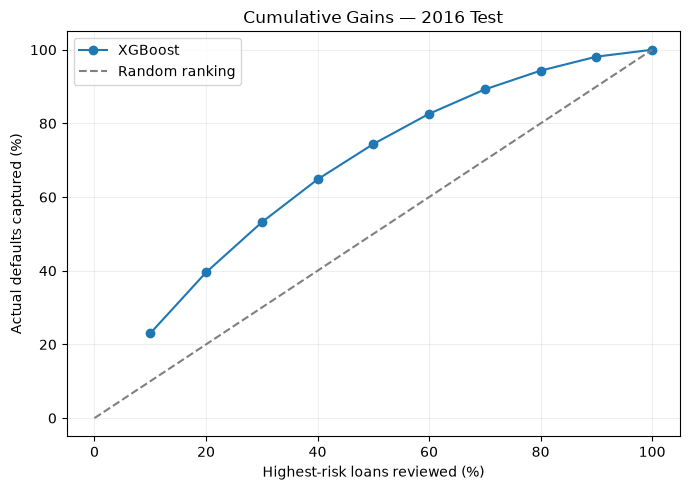

Overall default rate: 15.86%
Top 10% default rate: 36.50%
Top 10% lift: 2.3
Defaults captured in top 10%: 23.01%


In [6]:

# Rank loans by decreasing predicted risk
risk_df = pd.DataFrame({
    "score": p_test,
    "default": y_test,
}).sort_values("score", ascending=False).reset_index(drop=True)

n = len(risk_df)

# Decile 1 = highest-risk 10%
risk_df["risk_decile"] = (
    np.floor(np.arange(n) * 10 / n).astype(int) + 1
)

risk_summary = risk_df.groupby("risk_decile").agg(
    loans=("default", "size"),
    defaults=("default", "sum"),
    mean_score=("score", "mean"),
    default_rate=("default", "mean"),
)

overall_rate = y_test.mean()
total_defaults = y_test.sum()

risk_summary["lift"] = (
    risk_summary["default_rate"] / overall_rate
)

risk_summary["cumulative_loans_pct"] = (
    risk_summary["loans"].cumsum() / n * 100
)

risk_summary["defaults_captured_pct"] = (
    risk_summary["defaults"].cumsum()
    / total_defaults * 100
)

display(risk_summary.round(4))

# Cumulative gains curve
plt.figure(figsize=(7, 5))

plt.plot(
    risk_summary["cumulative_loans_pct"],
    risk_summary["defaults_captured_pct"],
    "o-",
    label="XGBoost",
)

plt.plot(
    [0, 100], [0, 100],
    "--", color="gray",
    label="Random ranking",
)

plt.xlabel("Highest-risk loans reviewed (%)")
plt.ylabel("Actual defaults captured (%)")
plt.title("Cumulative Gains — 2016 Test")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

top_10 = risk_summary.iloc[0]

print("Overall default rate:", f"{overall_rate:.2%}")
print("Top 10% default rate:", f"{top_10['default_rate']:.2%}")
print("Top 10% lift:", round(top_10["lift"], 2))
print(
    "Defaults captured in top 10%:",
    f"{top_10['defaults_captured_pct']:.2f}%"
)


### 05.6 — Risk Deciles and Lift: Results

XGBoost successfully concentrated actual defaults among higher-risk loans.

The highest-risk 10% had a default rate of 36.50%, compared with the overall rate of 15.86%, giving a lift of 2.30×. This group captured 23.01% of all defaults.

Reviewing the highest-risk 20%, 30%, and 50% captured 39.54%, 53.16%, and 74.41% of defaults, respectively.

These findings support using the model for risk ranking and prioritization rather than automatic loan rejection. The results were measured on the independent 2016 test set without modifying the model.



### 05.7 — Temporal Stability

We evaluate monthly performance across 2016 to examine changes in default prevalence, PR-AUC, ROC-AUC, and recall.

The objective is to assess whether the frozen model maintains consistent discrimination over time. All metrics use the original predictions and fixed threshold, without retraining or tuning.


,month,loans,default_rate,pr_auc,roc_auc,recall,mean_score
0,2016-01,22675,0.1458,0.3037,0.7208,0.5423,0.1259
1,2016-02,28609,0.1543,0.3141,0.7114,0.5632,0.1330
2,2016-03,44836,0.1614,0.3188,0.7210,0.6068,0.1373
3,2016-04,28106,0.1662,0.3284,0.7158,0.5986,0.1374
4,2016-05,21831,0.1714,0.3296,0.7092,0.6034,0.1424
5,2016-06,24600,0.1474,0.2901,0.6997,0.5105,0.1255
6,2016-07,25375,0.1697,0.3183,0.6968,0.6225,0.1487
7,2016-08,27179,0.1672,0.3097,0.6939,0.6084,0.1462
8,2016-09,21336,0.1611,0.2995,0.6931,0.6104,0.1466
9,2016-10,24738,0.1454,0.2618,0.6883,0.5932,0.1402


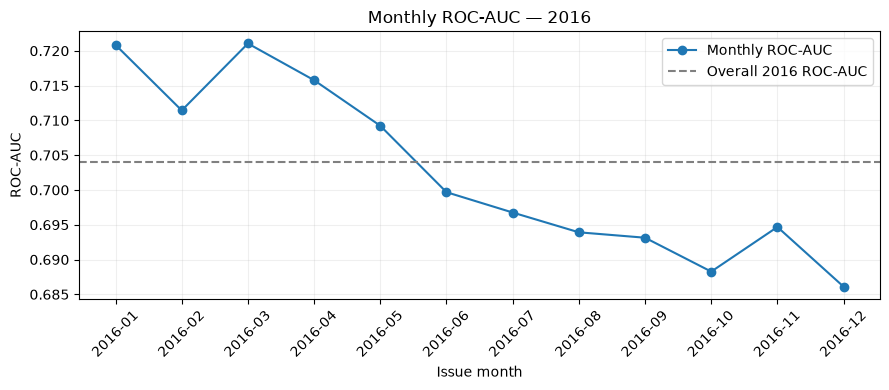

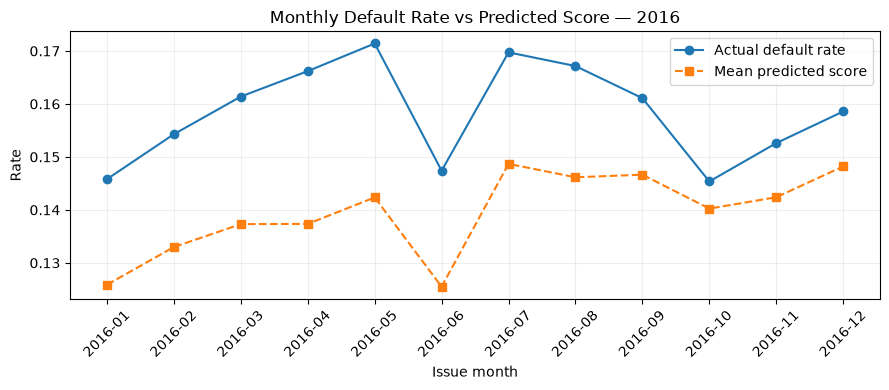

Monthly temporal evaluation complete.
No model or threshold changes.


In [7]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    recall_score,
)

monthly_df = pd.DataFrame({
    "month": test_dates.dt.to_period("M").astype(str).to_numpy(),
    "actual": y_test,
    "score": p_test,
    "predicted": y_pred,
})

monthly_results = []

for month, group in monthly_df.groupby("month", sort=True):
    y = group["actual"]
    scores = group["score"]

    monthly_results.append({
        "month": month,
        "loans": len(group),
        "default_rate": y.mean(),
        "pr_auc": average_precision_score(y, scores),
        "roc_auc": roc_auc_score(y, scores),
        "recall": recall_score(
            y, group["predicted"], zero_division=0
        ),
        "mean_score": scores.mean(),
    })

monthly_results = pd.DataFrame(monthly_results)

display(monthly_results.round(4))

# ROC-AUC by month
plt.figure(figsize=(9, 4))
plt.plot(
    monthly_results["month"],
    monthly_results["roc_auc"],
    "o-",
    label="Monthly ROC-AUC",
)
plt.axhline(
    roc_auc_score(y_test, p_test),
    linestyle="--",
    color="gray",
    label="Overall 2016 ROC-AUC",
)
plt.xlabel("Issue month")
plt.ylabel("ROC-AUC")
plt.title("Monthly ROC-AUC — 2016")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Actual default rate vs mean predicted score
plt.figure(figsize=(9, 4))
plt.plot(
    monthly_results["month"],
    monthly_results["default_rate"],
    "o-",
    label="Actual default rate",
)
plt.plot(
    monthly_results["month"],
    monthly_results["mean_score"],
    "s--",
    label="Mean predicted score",
)
plt.xlabel("Issue month")
plt.ylabel("Rate")
plt.title("Monthly Default Rate vs Predicted Score — 2016")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Monthly temporal evaluation complete.")
print("No model or threshold changes.")



### 05.7 — Temporal Stability: Results

Monthly ROC-AUC decreased from 0.7208 in January to 0.6861 in December 2016, indicating possible temporal performance degradation.

Monthly default rates varied between approximately 14.54% and 17.14%. Actual default rates exceeded mean predicted scores throughout the year, confirming persistent underestimation.

Despite the decline, the model maintained useful discrimination across all months. These findings highlight the importance of monitoring performance, data drift, and calibration over time.

No retraining or threshold adjustments were performed using the 2016 test set.



### 05.8 — Final Evaluation Conclusions

The frozen 55-feature XGBoost pipeline was evaluated on 323,375 independent 2016 loans.

**Key results:**
- PR-AUC: 0.3043, compared with the random baseline of 0.1586.
- ROC-AUC: 0.7040, indicating useful but moderate discrimination.
- F1-score: 0.3686, with precision 0.2675 and recall 0.5926.
- Confusion matrix: 30,401 true positives, 83,244 false positives, and 20,898 false negatives.
- Top-10% lift: 2.30×, capturing 23.01% of all defaults.
- Calibration: Systematic underestimation of observed default frequencies.
- Temporal stability: Monthly ROC-AUC declined during 2016.

**Final decision:** Retain the selected XGBoost pipeline as our primary model for exploratory loan-default risk ranking and screening. Its high false-positive rate, imperfect calibration, and temporal degradation limit its suitability for automated lending decisions.

The model, features, and classification threshold remained unchanged throughout the independent evaluation.
